<a href="https://colab.research.google.com/github/Ambartheanalyst-blip/Assignment-1/blob/main/Capstone_Project_AP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Heart Disease and Maximum Heart Rate

## Research Question
Is there a difference in average maximum heart rate between patients with heart disease and patients without heart disease in the Cleveland Heart Disease dataset?

## Motivation
This topic is relevant to healthcare and clinical research as it explores physiological differences across patient cohorts. The project compares one measurable characteristic (maximum heart rate) between two patient groups (patients with heart disease versus patients without heart disease). This analysis is strictly educational and does not provide medical advice or determine clinical causes of heart disease.

## Data Source
- **Dataset Name:** Cleveland Heart Disease Dataset
- **Source:** UCI Machine Learning Repository
- **Direct Data URL:** https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data
- **Dataset Information Page:** https://archive.ics.uci.edu/dataset/45/heart+disease

The dataset contains clinical and physiological measurements collected from patients evaluated for heart disease.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
df = pd.read_csv(
    url,
    header=None,
    na_values="?"
)

In [3]:
column_names = [
    "age",
    "sex",
    "chest_pain_type",
    "resting_blood_pressure",
    "cholesterol",
    "fasting_blood_sugar",
    "resting_ecg",
    "max_heart_rate",
    "exercise_induced_angina",
    "st_depression",
    "slope",
    "major_vessels",
    "thal",
    "heart_disease_status"
]

df.columns = column_names
display(df.head())

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_induced_angina,st_depression,slope,major_vessels,thal,heart_disease_status
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [4]:
print("Dataset Shape (Rows, Columns):")
print(df.shape)
print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumns:")
print(df.columns.tolist())

print("\nDataset Info:")
df.info()

print("\nDataset Description:")
display(df.describe())

Dataset Shape (Rows, Columns):
(303, 14)

Number of Rows: 303
Number of Columns: 14

Columns:
['age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol', 'fasting_blood_sugar', 'resting_ecg', 'max_heart_rate', 'exercise_induced_angina', 'st_depression', 'slope', 'major_vessels', 'thal', 'heart_disease_status']

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      303 non-null    float64
 1   sex                      303 non-null    float64
 2   chest_pain_type          303 non-null    float64
 3   resting_blood_pressure   303 non-null    float64
 4   cholesterol              303 non-null    float64
 5   fasting_blood_sugar      303 non-null    float64
 6   resting_ecg              303 non-null    float64
 7   max_heart_rate           303 non-null    float64
 8   exercise

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_induced_angina,st_depression,slope,major_vessels,thal,heart_disease_status
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [5]:
print("Missing values per column:")
print(df.isnull().sum())

total_missing = df.isnull().sum().sum()
print(f"\nTotal number of missing values in the dataset: {total_missing}")
print("\nExplanation: In the original UCI Cleveland Heart Disease dataset, missing values are denoted by the question-mark symbol ('?'). These were loaded as NaN (missing values) using na_values='?'.")

Missing values per column:
age                        0
sex                        0
chest_pain_type            0
resting_blood_pressure     0
cholesterol                0
fasting_blood_sugar        0
resting_ecg                0
max_heart_rate             0
exercise_induced_angina    0
st_depression              0
slope                      0
major_vessels              4
thal                       2
heart_disease_status       0
dtype: int64

Total number of missing values in the dataset: 6

Explanation: In the original UCI Cleveland Heart Disease dataset, missing values are denoted by the question-mark symbol ('?'). These were loaded as NaN (missing values) using na_values='?'.


In [6]:
# Preserve the original DataFrame df and create analysis_df
analysis_df = df[["max_heart_rate", "heart_disease_status"]].copy()

rows_before = len(analysis_df)

# Convert columns to numeric, coercing invalid entries to NaN
analysis_df["max_heart_rate"] = pd.to_numeric(analysis_df["max_heart_rate"], errors="coerce")
analysis_df["heart_disease_status"] = pd.to_numeric(analysis_df["heart_disease_status"], errors="coerce")

# Drop rows missing either variable
analysis_df = analysis_df.dropna(subset=["max_heart_rate", "heart_disease_status"])

rows_after = len(analysis_df)
rows_removed = rows_before - rows_after

print(f"Rows before cleaning: {rows_before}")
print(f"Rows after cleaning: {rows_after}")
print(f"Rows removed: {rows_removed}")

Rows before cleaning: 303
Rows after cleaning: 303
Rows removed: 0


In [7]:
# Create heart_disease_group column
analysis_df["heart_disease_group"] = analysis_df["heart_disease_status"].apply(
    lambda x: "No Heart Disease" if x == 0 else "Heart Disease"
)

group_counts = analysis_df["heart_disease_group"].value_counts()
print("Number of observations in each group:")
print(group_counts)

Number of observations in each group:
heart_disease_group
No Heart Disease    164
Heart Disease       139
Name: count, dtype: int64


In [8]:
# Calculate descriptive statistics for max_heart_rate within each group
desc_stats = analysis_df.groupby("heart_disease_group")["max_heart_rate"].agg(
    Count="count",
    Mean="mean",
    Median="median",
    Std_Dev="std",
    Min="min",
    Max="max"
).round(2)

print("Descriptive Statistics for Maximum Heart Rate by Group:")
display(desc_stats)

# Calculate group means and difference (No Heart Disease minus Heart Disease)
mean_no_hd = desc_stats.loc["No Heart Disease", "Mean"]
mean_hd = desc_stats.loc["Heart Disease", "Mean"]
mean_diff = mean_no_hd - mean_hd

print(f"\nMean maximum heart rate for No Heart Disease: {mean_no_hd}")
print(f"Mean maximum heart rate for Heart Disease: {mean_hd}")
print(f"Difference (No Heart Disease minus Heart Disease): {mean_diff:.2f}")

Descriptive Statistics for Maximum Heart Rate by Group:


,Count,Mean,Median,Std_Dev,Min,Max
heart_disease_group,,,,,,
Heart Disease,139,139.26,142.0,22.59,71.0,195.0
No Heart Disease,164,158.38,161.0,19.20,96.0,202.0



Mean maximum heart rate for No Heart Disease: 158.38
Mean maximum heart rate for Heart Disease: 139.26
Difference (No Heart Disease minus Heart Disease): 19.12


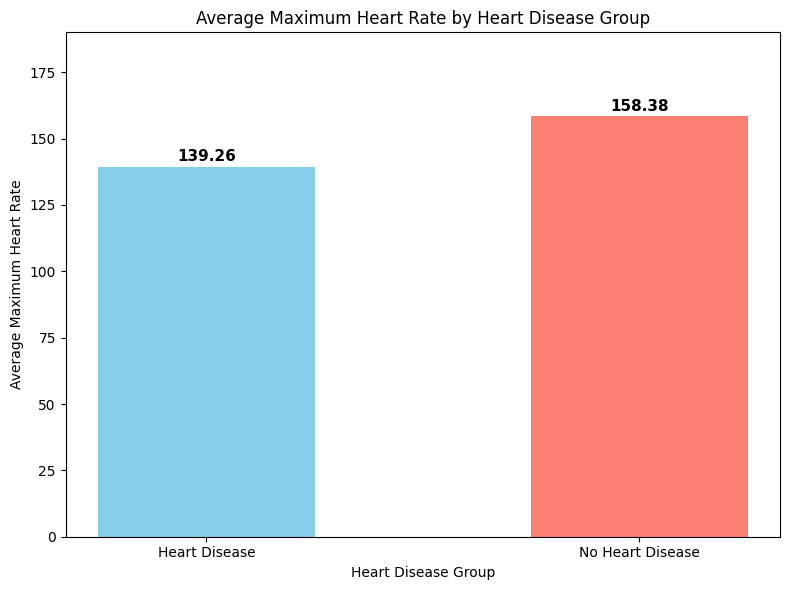

In [9]:
# Bar chart comparing average maximum heart rate
group_means = analysis_df.groupby("heart_disease_group")["max_heart_rate"].mean()

plt.figure(figsize=(8, 6))
bars = plt.bar(group_means.index, group_means.values, color=["skyblue", "salmon"], width=0.5)

plt.title("Average Maximum Heart Rate by Heart Disease Group")
plt.xlabel("Heart Disease Group")
plt.ylabel("Average Maximum Heart Rate")
plt.ylim(0, max(group_means.values) * 1.2)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 1, f"{height:.2f}",
             ha="center", va="bottom", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

## Explanation of Visualization 1
Patients without heart disease exhibit a higher average maximum heart rate compared to patients diagnosed with heart disease. This visual comparison highlights a central difference between the two cohorts, though we must examine inferential statistics before determining statistical significance.

/tmp/ipykernel_1500/1585681120.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([no_disease_hr, disease_hr], labels=["No Heart Disease", "Heart Disease"], patch_artist=True,


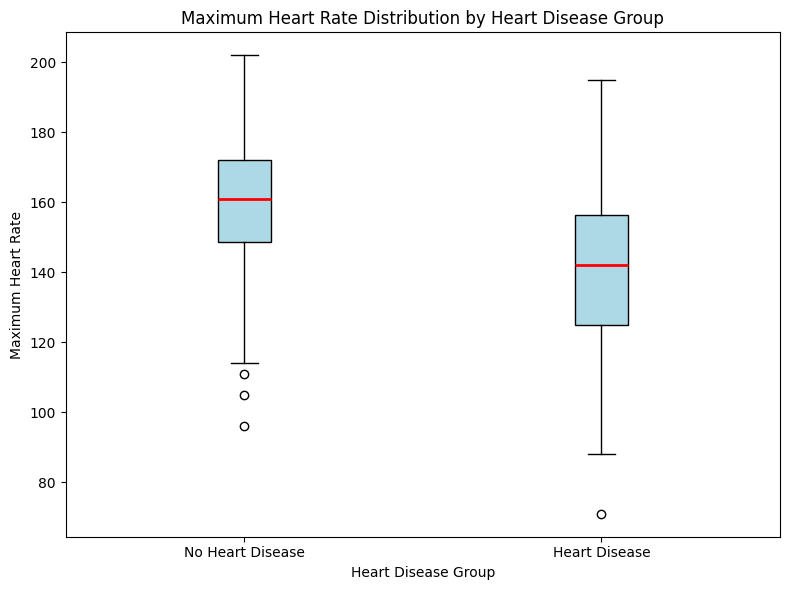

In [10]:
# Boxplot comparing the distribution of maximum heart rate
no_disease_hr = analysis_df[analysis_df["heart_disease_group"] == "No Heart Disease"]["max_heart_rate"]
disease_hr = analysis_df[analysis_df["heart_disease_group"] == "Heart Disease"]["max_heart_rate"]

plt.figure(figsize=(8, 6))
plt.boxplot([no_disease_hr, disease_hr], labels=["No Heart Disease", "Heart Disease"], patch_artist=True,
            boxprops=dict(facecolor="lightblue", color="black"),
            medianprops=dict(color="red", linewidth=2))

plt.title("Maximum Heart Rate Distribution by Heart Disease Group")
plt.xlabel("Heart Disease Group")
plt.ylabel("Maximum Heart Rate")
plt.tight_layout()
plt.show()

## Explanation of Visualization 2
The boxplot displays the median, spread, and overall distribution of maximum heart rates for both groups. The median maximum heart rate is visibly higher for the "No Heart Disease" group, and while there is considerable overlap in the distributions, the interquartile ranges differ. A visual graph alone cannot determine statistical significance without formal testing.

## Hypotheses
- **Null Hypothesis ($H_0$):** The mean maximum heart rate is the same for patients with heart disease and patients without heart disease ($\mu_1 = \mu_2$).
- **Alternative Hypothesis ($H_a$):** The mean maximum heart rate is different between patients with heart disease and patients without heart disease ($\mu_1 \neq \mu_2$).
- **Significance Level ($\alpha$):** 0.05

In [11]:
# Independent-samples t-test (Welch's t-test)
t_stat, p_val = stats.ttest_ind(
    no_disease_hr,
    disease_hr,
    equal_var=False,
    nan_policy="omit"
)

alpha = 0.05

print(f"Mean for No Heart Disease: {mean_no_hd:.2f}")
print(f"Mean for Heart Disease: {mean_hd:.2f}")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_val:.4e}")
print(f"Alpha level: {alpha}")

if p_val < alpha:
    print("\nDecision: Reject the null hypothesis.")
    print("Result: The difference in average maximum heart rate between the two groups is statistically significant.")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("Result: The difference in average maximum heart rate between the two groups is not statistically significant.")

Mean for No Heart Disease: 158.38
Mean for Heart Disease: 139.26
T-statistic: 7.8579
P-value: 9.1062e-14
Alpha level: 0.05

Decision: Reject the null hypothesis.
Result: The difference in average maximum heart rate between the two groups is statistically significant.


In [12]:
cleaned_obs = len(analysis_df)
count_no_disease = len(no_disease_hr)
count_disease = len(disease_hr)

print("=== KEY RESULTS SUMMARY ===")
print(f"Number of cleaned observations: {cleaned_obs}")
print(f"Observations in 'No Heart Disease' group: {count_no_disease}")
print(f"Observations in 'Heart Disease' group: {count_disease}")
print(f"Mean maximum heart rate (No Heart Disease): {mean_no_hd:.2f}")
print(f"Mean maximum heart rate (Heart Disease): {mean_hd:.2f}")
print(f"Difference in means (No Heart Disease minus Heart Disease): {mean_diff:.2f}")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_val:.4e}")
if p_val < alpha:
    print("Statistical-test decision: Reject the null hypothesis (Statistically Significant)")
else:
    print("Statistical-test decision: Fail to reject the null hypothesis (Not Statistically Significant)")

=== KEY RESULTS SUMMARY ===
Number of cleaned observations: 303
Observations in 'No Heart Disease' group: 164
Observations in 'Heart Disease' group: 139
Mean maximum heart rate (No Heart Disease): 158.38
Mean maximum heart rate (Heart Disease): 139.26
Difference in means (No Heart Disease minus Heart Disease): 19.12
T-statistic: 7.8579
P-value: 9.1062e-14
Statistical-test decision: Reject the null hypothesis (Statistically Significant)


In [13]:
# Automatic short conclusion using actual calculated values
sig_text = "is statistically significant" if p_val < alpha else "is not statistically significant"
conclusion_text = (
    f"Patients without heart disease had a higher average maximum heart rate ({mean_no_hd:.2f}) "
    f"compared to patients with heart disease ({mean_hd:.2f}). "
    f"With a p-value of {p_val:.4e}, this difference {sig_text} at the alpha level of {alpha}. "
    "This analysis demonstrates an association between maximum heart rate and heart disease status in this dataset, but does not establish causation."
)

print("=== CONCLUSION ===")
print(conclusion_text)

=== CONCLUSION ===
Patients without heart disease had a higher average maximum heart rate (158.38) compared to patients with heart disease (139.26). With a p-value of 9.1062e-14, this difference is statistically significant at the alpha level of 0.05. This analysis demonstrates an association between maximum heart rate and heart disease status in this dataset, but does not establish causation.


## References
- UCI Machine Learning Repository. Heart Disease Dataset.
  - Dataset information: https://archive.ics.uci.edu/dataset/45/heart+disease
  - Direct data: https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data